In [3]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.cluster import KMeans

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    silhouette_score
)

import matplotlib.pyplot as plt

In [1]:
import sys
print(sys.executable)

E:\Commerce360\venv\Scripts\python.exe


In [4]:
sales = pd.read_csv("../data/processed/sales_features.csv")
customers = pd.read_csv("../data/processed/customer_features.csv")
delivery = pd.read_csv("../data/processed/delivery_features.csv")

print("Sales:", sales.shape)
print("Customers:", customers.shape)
print("Delivery:", delivery.shape)

Sales: (112650, 35)
Customers: (98666, 8)
Delivery: (113425, 23)


In [5]:
delivery_ml = delivery[
    [
        "order_id",
        "delivery_days",
        "delivery_delay_days",
        "on_time_flag"
    ]
].copy()

delivery_ml = delivery_ml.dropna()

display(delivery_ml.head())

,order_id,delivery_days,delivery_delay_days,on_time_flag
0,e481f51cbdc54678b7cc49136f2d6af7,8.0,-8.0,1
1,53cdb2fc8bc7dce0b6741e2150273451,13.0,-6.0,1
2,47770eb9100c2d0c44946d9cf07ec65d,9.0,-18.0,1
3,949d5b44dbf5de918fe9c16f97b45f8a,13.0,-13.0,1
4,ad21c59c0840e6cb83a9ceb5573f8159,2.0,-10.0,1


In [5]:
print(delivery_ml["on_time_flag"].value_counts())

on_time_flag
1    102931
0      7265
Name: count, dtype: int64


In [6]:
X = delivery_ml[
    [
        "delivery_days"
    ]
]

y = delivery_ml["on_time_flag"]

In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (88156, 1)
Testing data: (22040, 1)


In [8]:
logistic_model = LogisticRegression()

logistic_model.fit(
    X_train,
    y_train
)

y_pred_logistic = logistic_model.predict(X_test)

print(
    "Logistic Regression Accuracy:",
    round(accuracy_score(y_test, y_pred_logistic), 4)
)

Logistic Regression Accuracy: 0.9595


In [9]:
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

rf_model.fit(
    X_train,
    y_train
)

y_pred_rf = rf_model.predict(X_test)

print(
    "Random Forest Accuracy:",
    round(accuracy_score(y_test, y_pred_rf), 4)
)

Random Forest Accuracy: 0.9581


In [10]:
print("Random Forest Classification Report")
print(
    classification_report(
        y_test,
        y_pred_rf
    )
)

Random Forest Classification Report
              precision    recall  f1-score   support

           0       0.71      0.62      0.66      1453
           1       0.97      0.98      0.98     20587

    accuracy                           0.96     22040
   macro avg       0.84      0.80      0.82     22040
weighted avg       0.96      0.96      0.96     22040



In [11]:
cm = confusion_matrix(
    y_test,
    y_pred_rf
)

print(cm)

[[  898   555]
 [  368 20219]]


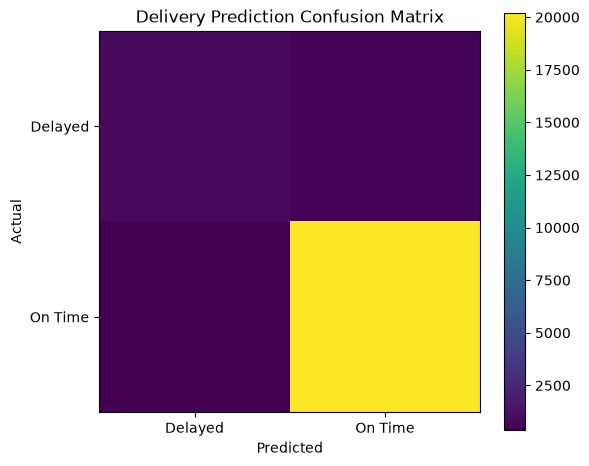

In [12]:
plt.figure(figsize=(6, 5))

plt.imshow(cm)

plt.title("Delivery Prediction Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.xticks([0, 1], ["Delayed", "On Time"])
plt.yticks([0, 1], ["Delayed", "On Time"])

plt.colorbar()

plt.tight_layout()
plt.show()

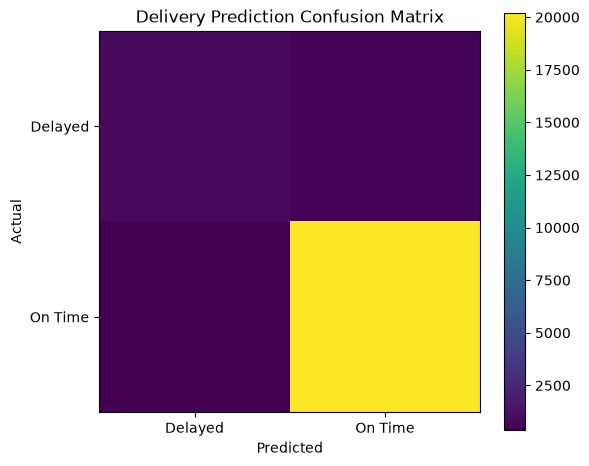

In [13]:
plt.figure(figsize=(6, 5))

plt.imshow(cm)

plt.title("Delivery Prediction Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.xticks([0, 1], ["Delayed", "On Time"])
plt.yticks([0, 1], ["Delayed", "On Time"])

plt.colorbar()

plt.tight_layout()
plt.show()

In [14]:
customer_ml = customers[
    [
        "customer_id",
        "total_orders",
        "total_spending",
        "average_order_value",
        "total_items",
        "customer_recency_days"
    ]
].copy()

customer_ml = customer_ml.dropna()

display(customer_ml.head())

,customer_id,total_orders,total_spending,average_order_value,total_items,customer_recency_days
0,00012a2ce6f8dcda20d059ce98491703,1,114.74,114.74,1,292
1,000161a058600d5901f007fab4c27140,1,67.41,67.41,1,413
2,0001fd6190edaaf884bcaf3d49edf079,1,195.42,195.42,1,551
3,0002414f95344307404f0ace7a26f1d5,1,179.35,179.35,1,382
4,000379cdec625522490c315e70c7a9fb,1,107.01,107.01,1,153


In [19]:
customer_features_ml = customer_ml[
    [
        "total_orders",
        "total_spending",
        "average_order_value",
        "total_items",
        "customer_recency_days"
    ]
]

print("Customer features created successfully.")

Customer features created successfully.


In [20]:
scaler = StandardScaler()

customer_scaled = scaler.fit_transform(
    customer_features_ml
)

print("Customer data scaled successfully.")

Customer data scaled successfully.


In [21]:
kmeans = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

customer_ml["segment"] = kmeans.fit_predict(
    customer_scaled
)

display(
    customer_ml[
        [
            "customer_id",
            "total_orders",
            "total_spending",
            "customer_recency_days",
            "segment"
        ]
    ].head(10)
)

,customer_id,total_orders,total_spending,customer_recency_days,segment
0,00012a2ce6f8dcda20d059ce98491703,1,114.74,292,0
1,000161a058600d5901f007fab4c27140,1,67.41,413,0
2,0001fd6190edaaf884bcaf3d49edf079,1,195.42,551,0
3,0002414f95344307404f0ace7a26f1d5,1,179.35,382,0
4,000379cdec625522490c315e70c7a9fb,1,107.01,153,1
5,0004164d20a9e969af783496f3408652,1,71.80,509,0
6,000419c5494106c306a97b5635748086,1,49.40,184,1
7,00046a560d407e99b969756e0b10f282,1,166.59,258,1
8,00050bf6e01e69d5c0fd612f1bcfb69c,1,85.23,350,0
9,000598caf2ef4117407665ac33275130,1,1255.71,22,3


In [22]:
segment_summary = (
    customer_ml
    .groupby("segment")
    .agg(
        customers=("customer_id", "count"),
        avg_orders=("total_orders", "mean"),
        avg_spending=("total_spending", "mean"),
        avg_order_value=("average_order_value", "mean"),
        avg_recency=("customer_recency_days", "mean")
    )
    .reset_index()
)

display(segment_summary)

,segment,customers,avg_orders,avg_spending,avg_order_value,avg_recency
0,0,39735,1.0,127.227438,119.604347,394.525733
1,1,53813,1.0,129.735647,122.326221,134.144593
2,2,2259,1.0,341.616534,89.478499,241.484728
3,3,2859,1.0,1061.558185,1006.894169,249.835257


In [28]:
# Fast Silhouette Score using a sample
sample_size = min(5000, len(customer_scaled))

silhouette = silhouette_score(
    customer_scaled,
    customer_ml["segment"],
    sample_size=sample_size,
    random_state=42
)

print("Silhouette Score:", round(silhouette, 4))
print("Sample size:", sample_size)

Silhouette Score: 0.3958
Sample size: 5000


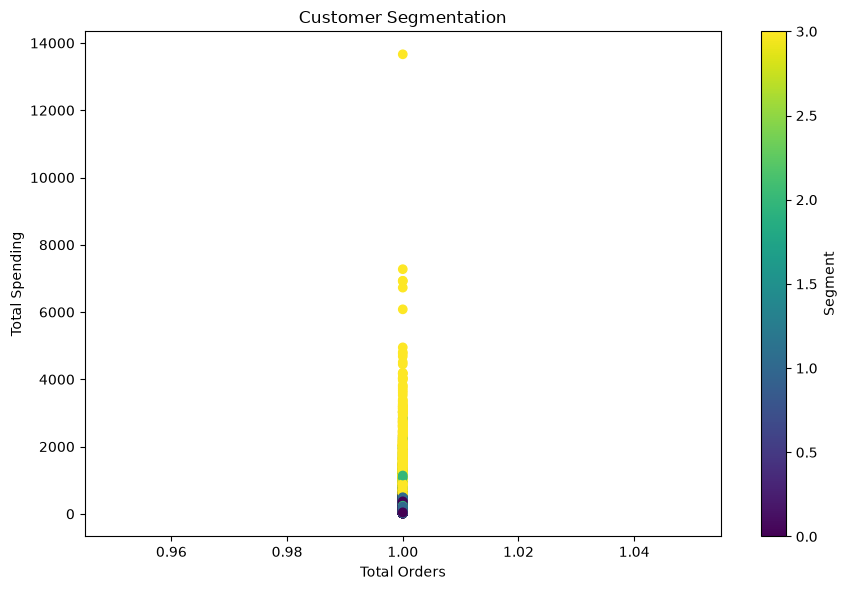

In [29]:
plt.figure(figsize=(9, 6))

plt.scatter(
    customer_ml["total_orders"],
    customer_ml["total_spending"],
    c=customer_ml["segment"]
)

plt.title("Customer Segmentation")
plt.xlabel("Total Orders")
plt.ylabel("Total Spending")
plt.colorbar(label="Segment")

plt.tight_layout()
plt.show()

In [30]:
segment_summary["segment_name"] = (
    "Customer Segment " +
    segment_summary["segment"].astype(str)
)

display(segment_summary)

,segment,customers,avg_orders,avg_spending,avg_order_value,avg_recency,segment_name
0,0,39735,1.0,127.227438,119.604347,394.525733,Customer Segment 0
1,1,53813,1.0,129.735647,122.326221,134.144593,Customer Segment 1
2,2,2259,1.0,341.616534,89.478499,241.484728,Customer Segment 2
3,3,2859,1.0,1061.558185,1006.894169,249.835257,Customer Segment 3


In [31]:
customer_ml.to_csv(
    "../data/processed/customer_segments.csv",
    index=False
)

print("customer_segments.csv saved successfully.")

customer_segments.csv saved successfully.


In [32]:
ml_results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Random Forest"
    ],
    "Accuracy": [
        accuracy_score(y_test, y_pred_logistic),
        accuracy_score(y_test, y_pred_rf)
    ]
})

display(ml_results)

ml_results.to_csv(
    "../data/processed/ml_model_results.csv",
    index=False
)

print("ML results saved successfully.")

,Model,Accuracy
0,Logistic Regression,0.959528
1,Random Forest,0.958122


ML results saved successfully.
